# Étape 10 : analyse exploratoire

But : connaître les données avant de construire un modèle. On regarde ce qu'il y a
dans la base, comment les parties se répartissent, et quels signaux de l'état
**à 15 minutes** vont avec la victoire.

Ce notebook ne fait que **lire** la base (aucune écriture). Il ne prouve rien :
il fait apparaître des pistes, que l'étape 11 testera proprement
(régression logistique avec variables de contrôle, intervalles de confiance).

Plan :
1. Connexion à la base
2. Vue d'ensemble : volume, patchs, dates
3. Durée des parties
4. Côté bleu ou rouge
5. L'état de la partie à 15 min et la victoire
6. Les « premiers » objectifs (premier sang, première tour, premier dragon)
7. Champions
8. L'échantillon : joueurs répétés
9. Conclusions et questions pour l'étape 11

## 1. Connexion à la base

Avant de lancer : Docker Desktop ouvert et `docker compose start` fait.

`query()` envoie une requête SQL à PostgreSQL et renvoie un tableau pandas
(DataFrame). Le gros du travail (jointures, sommes, filtres) est fait en SQL,
dans la base ; Python ne reçoit que le résultat, déjà petit.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from dotenv import load_dotenv

# Le notebook tourne depuis notebooks/ : la racine du projet est le dossier parent.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(ROOT / ".env")
DATABASE_URL = os.environ["DATABASE_URL"]


def query(sql, params=None):
    """Exécute une requête SELECT et renvoie le résultat en DataFrame."""
    with psycopg.connect(DATABASE_URL) as conn:
        cur = conn.execute(sql, params)
        columns = [col.name for col in cur.description]
        return pd.DataFrame(cur.fetchall(), columns=columns)


def prop_ci(successes, n, z=1.96):
    """Proportion et intervalle de confiance à 95 % (approximation normale)."""
    p = successes / n
    half = z * np.sqrt(p * (1 - p) / n)
    return p, p - half, p + half


plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:.3f}".format)

query("SELECT count(*) AS parties FROM matches")

,parties
0,4907


## 2. Vue d'ensemble

Combien de lignes dans chaque table, de quand datent les parties, et de quels patchs.
Le patch compte : chaque patch change l'équilibre du jeu (champions, objectifs),
donc des parties de patchs très différents ne se comparent pas forcément.

In [2]:
tables = ["matches", "teams", "players", "participants",
          "participant_frames", "events", "event_assists"]
counts = {t: query(f"SELECT count(*) AS n FROM {t}")["n"][0] for t in tables}
pd.Series(counts, name="lignes").to_frame()

,lignes
matches,4907
teams,9814
players,41173
participants,49070
participant_frames,1540740
events,729999
event_assists,532538


In [3]:
query("""
    SELECT min(game_creation)::date AS premiere_partie,
           max(game_creation)::date AS derniere_partie
    FROM matches
""")

,premiere_partie,derniere_partie
0,2025-07-19,2026-10-28


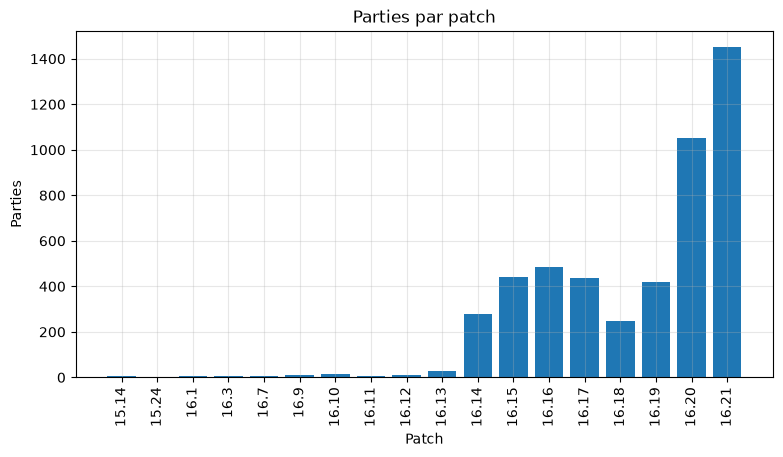

8 patchs ont au moins 200 parties : 16.14, 16.15, 16.16, 16.17, 16.18, 16.19, 16.20, 16.21
Ils couvrent 98% des parties.


In [4]:
patches = query("""
    SELECT split_part(game_version, '.', 1)::int AS majeur,
           split_part(game_version, '.', 2)::int AS mineur,
           count(*) AS parties
    FROM matches
    GROUP BY 1, 2
    ORDER BY 1, 2
""")
patches["patch"] = patches["majeur"].astype(str) + "." + patches["mineur"].astype(str)

fig, ax = plt.subplots()
ax.bar(patches["patch"], patches["parties"])
ax.set_title("Parties par patch")
ax.set_xlabel("Patch")
ax.set_ylabel("Parties")
ax.tick_params(axis="x", rotation=90)
plt.show()

recent = patches[patches["parties"] >= 200]
print(f"{len(recent)} patchs ont au moins 200 parties : {', '.join(recent['patch'])}")
print(f"Ils couvrent {recent['parties'].sum() / patches['parties'].sum():.0%} des parties.")

## 3. Durée des parties

On repère deux choses : la forme générale, et des pics éventuels aux minutes où
l'équipe qui perd a le droit d'abandonner (vote à 15 min s'il est unanime, à 20 min
sinon). La ligne rouge marque 15 min : les parties plus courtes n'ont pas d'état
« à 15 min » et seront exclues du modèle.

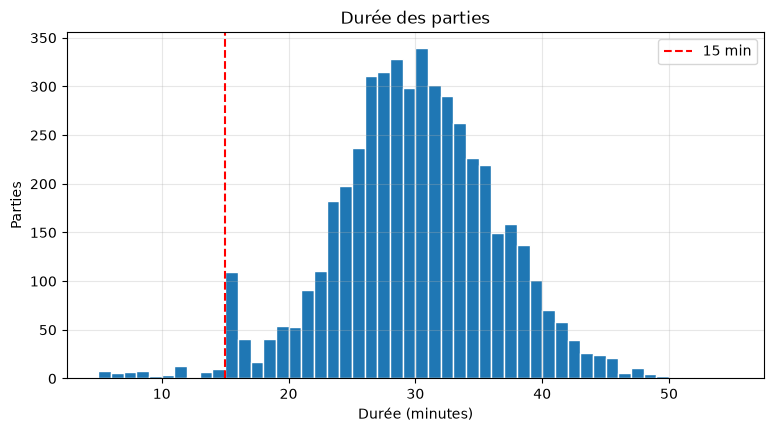

count   4907.000
mean      29.900
std        6.583
min        5.017
10%       22.150
25%       26.083
50%       30.000
75%       34.150
90%       38.117
max       52.300
Name: duree_min, dtype: float64

In [5]:
matches = query("""
    SELECT match_id,
           game_duration_s / 60.0 AS duree_min,
           split_part(game_version, '.', 1) || '.' || split_part(game_version, '.', 2) AS patch
    FROM matches
""")
matches["duree_min"] = matches["duree_min"].astype(float)

fig, ax = plt.subplots()
ax.hist(matches["duree_min"], bins=np.arange(5, 56, 1), edgecolor="white")
ax.axvline(15, color="red", linestyle="--", label="15 min")
ax.set_title("Durée des parties")
ax.set_xlabel("Durée (minutes)")
ax.set_ylabel("Parties")
ax.legend()
plt.show()

matches["duree_min"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])

In [6]:
n = len(matches)
for lo, hi in [(5, 15), (15, 16), (20, 21), (21, 22)]:
    k = matches["duree_min"].between(lo, hi, inclusive="left").sum()
    print(f"Entre {lo} et {hi} min : {k} parties ({k / n:.1%})")

Entre 5 et 15 min : 68 parties (1.4%)
Entre 15 et 16 min : 109 parties (2.2%)
Entre 20 et 21 min : 53 parties (1.1%)
Entre 21 et 22 min : 91 parties (1.9%)


## 4. Côté bleu ou rouge

Une équipe joue en bas à gauche de la carte (bleue, 100), l'autre en haut à droite
(rouge, 200). On mesure le taux de victoire du côté bleu, avec un intervalle de
confiance à 95 % : la plage où se trouve probablement la vraie valeur.
Si 50 % est hors de la plage, l'écart n'est probablement pas dû au hasard.

In [7]:
side = query("SELECT count(*) AS n, sum(win::int) AS victoires FROM teams WHERE team_id = 100")
p, lo, hi = prop_ci(side["victoires"][0], side["n"][0])
print(f"Victoires du côté bleu : {p:.1%} (IC 95 % : {lo:.1%} à {hi:.1%}) sur {side['n'][0]} parties")

Victoires du côté bleu : 48.3% (IC 95 % : 46.9% à 49.7%) sur 4907 parties


## 5. L'état de la partie à 15 min et la victoire

C'est le cœur du projet : à 15 min, quels écarts entre les deux équipes vont avec la victoire ?

Pour chaque partie, on calcule des **écarts bleu moins rouge** (positif = le bleu mène) :
- or, XP et CS (sbires + monstres) : lus dans `participant_frames` à la minute 15 ;
- kills, tours, plaques et dragons : comptés dans `events` avant 15:00.

Écart plutôt que valeurs des deux équipes : une seule colonne par signal, et c'est
l'avance qui compte, pas le total (le total dépend surtout du rythme de la partie).

In [8]:
state15 = query("""
    WITH frames15 AS (
        SELECT f.match_id,
               sum(CASE WHEN p.team_id = 100 THEN 1 ELSE -1 END * f.total_gold) AS gold_diff,
               sum(CASE WHEN p.team_id = 100 THEN 1 ELSE -1 END * f.xp) AS xp_diff,
               sum(CASE WHEN p.team_id = 100 THEN 1 ELSE -1 END
                   * (f.minions_killed + f.jungle_minions_killed)) AS cs_diff
        FROM participant_frames f
        JOIN participants p USING (match_id, participant_id)
        WHERE f.minute = 15
        GROUP BY f.match_id
    ),
    events15 AS (
        SELECT match_id,
               sum(CASE WHEN killer_team_id = 100 THEN 1 ELSE -1 END)
                   FILTER (WHERE event_type = 'CHAMPION_KILL') AS kills_diff,
               sum(CASE WHEN killer_team_id = 100 THEN 1 ELSE -1 END)
                   FILTER (WHERE event_type = 'BUILDING_KILL') AS towers_diff,
               sum(CASE WHEN killer_team_id = 100 THEN 1 ELSE -1 END)
                   FILTER (WHERE event_type = 'TURRET_PLATE_DESTROYED') AS plates_diff,
               sum(CASE WHEN killer_team_id = 100 THEN 1 ELSE -1 END)
                   FILTER (WHERE monster_type = 'DRAGON') AS dragons_diff
        FROM events
        WHERE timestamp_ms < 15 * 60 * 1000
          AND killer_team_id IS NOT NULL
        GROUP BY match_id
    )
    SELECT f.match_id,
           f.gold_diff, f.xp_diff, f.cs_diff,
           coalesce(e.kills_diff, 0)   AS kills_diff,
           coalesce(e.towers_diff, 0)  AS towers_diff,
           coalesce(e.plates_diff, 0)  AS plates_diff,
           coalesce(e.dragons_diff, 0) AS dragons_diff,
           t.win::int AS blue_win
    FROM frames15 f
    JOIN teams t ON t.match_id = f.match_id AND t.team_id = 100
    LEFT JOIN events15 e ON e.match_id = f.match_id
""")
FEATURES = ["gold_diff", "xp_diff", "cs_diff", "kills_diff",
            "towers_diff", "plates_diff", "dragons_diff"]
state15[FEATURES + ["blue_win"]] = state15[FEATURES + ["blue_win"]].astype(int)

print(f"{len(state15)} parties ont une minute 15 ({len(matches) - len(state15)} exclues).")
state15[FEATURES].describe().T

4849 parties ont une minute 15 (58 exclues).


,count,mean,std,min,25%,50%,75%,max
gold_diff,4849.000,34.400,3998.097,-17871.000,-2560.000,3.000,2661.000,12911.000
xp_diff,4849.000,-12.380,3511.301,-14099.000,-2389.000,-26.000,2358.000,11802.000
cs_diff,4849.000,0.251,55.904,-196.000,-36.000,0.000,38.000,210.000
kills_diff,4849.000,0.108,7.198,-31.000,-5.000,0.000,5.000,25.000
towers_diff,4849.000,0.025,1.419,-11.000,-1.000,0.000,1.000,6.000
plates_diff,4849.000,0.145,6.868,-37.000,-4.000,0.000,4.000,31.000
dragons_diff,4849.000,-0.173,1.384,-2.000,-1.000,0.000,1.000,2.000


### 5.1 L'écart d'or à 15 min

D'abord la répartition de l'écart d'or, puis le taux de victoire du bleu selon cet écart.
Pour la 2e figure, on range les parties en 10 groupes de même taille (déciles)
selon l'écart d'or, et on calcule le taux de victoire de chaque groupe
avec son intervalle de confiance (barre verticale).

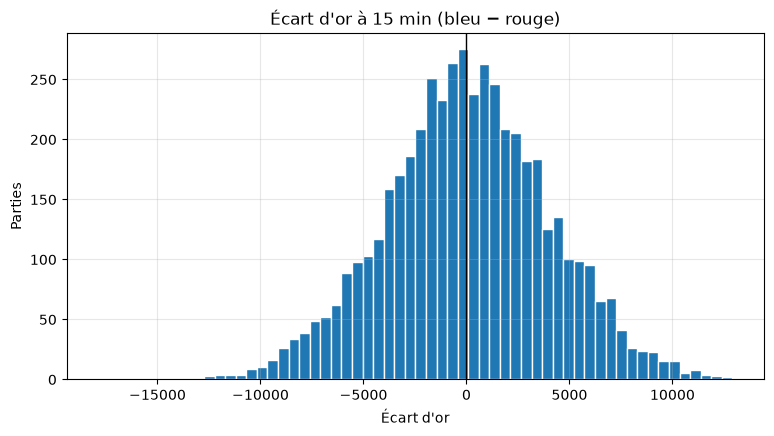

Écart absolu médian : 2603 or
Parties avec un écart de 3 000 or ou plus à 15 min : 44.2%


In [9]:
fig, ax = plt.subplots()
ax.hist(state15["gold_diff"], bins=60, edgecolor="white")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Écart d'or à 15 min (bleu − rouge)")
ax.set_xlabel("Écart d'or")
ax.set_ylabel("Parties")
plt.show()

big = (state15["gold_diff"].abs() >= 3000).mean()
print(f"Écart absolu médian : {state15['gold_diff'].abs().median():.0f} or")
print(f"Parties avec un écart de 3 000 or ou plus à 15 min : {big:.1%}")

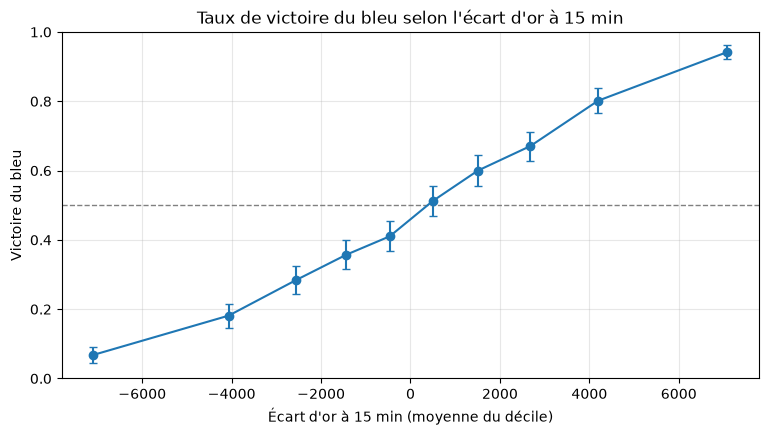

,x,n,wins,p,lo,hi
gold_diff,,,,,,
"(-17871.001, -5124.2]",-7093.035,485,33,0.068,0.046,0.090
"(-5124.2, -3270.8]",-4066.509,485,88,0.181,0.147,0.216
"(-3270.8, -1937.0]",-2560.837,486,138,0.284,0.244,0.324
"(-1937.0, -919.6]",-1432.027,484,173,0.357,0.315,0.400
"(-919.6, 3.0]",-464.544,485,199,0.410,0.367,0.454
"(3.0, 956.8]",499.283,484,248,0.512,0.468,0.557
"(956.8, 2060.4]",1506.625,485,291,0.600,0.556,0.644
"(2060.4, 3325.0]",2680.016,486,326,0.671,0.629,0.713
"(3325.0, 5236.2]",4194.407,484,388,0.802,0.766,0.837


In [10]:
def winrate_by_decile(df, feature):
    """Taux de victoire du bleu par décile d'une variable, avec IC 95 %."""
    groups = pd.qcut(df[feature], q=10, duplicates="drop")
    out = df.groupby(groups, observed=True).agg(
        x=(feature, "mean"), n=("blue_win", "size"), wins=("blue_win", "sum"))
    out["p"], out["lo"], out["hi"] = prop_ci(out["wins"], out["n"])
    return out


def plot_winrate(ax, table, xlabel):
    ax.errorbar(table["x"], table["p"],
                yerr=[table["p"] - table["lo"], table["hi"] - table["p"]],
                fmt="o-", capsize=3)
    ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Victoire du bleu")


gold_table = winrate_by_decile(state15, "gold_diff")
fig, ax = plt.subplots()
plot_winrate(ax, gold_table, "Écart d'or à 15 min (moyenne du décile)")
ax.set_title("Taux de victoire du bleu selon l'écart d'or à 15 min")
plt.show()
gold_table

### 5.2 Les autres écarts

Même figure pour l'XP, le CS, les kills et les plaques. Les tours et les dragons
prennent trop peu de valeurs différentes avant 15 min pour des déciles :
on les regarde valeur par valeur.

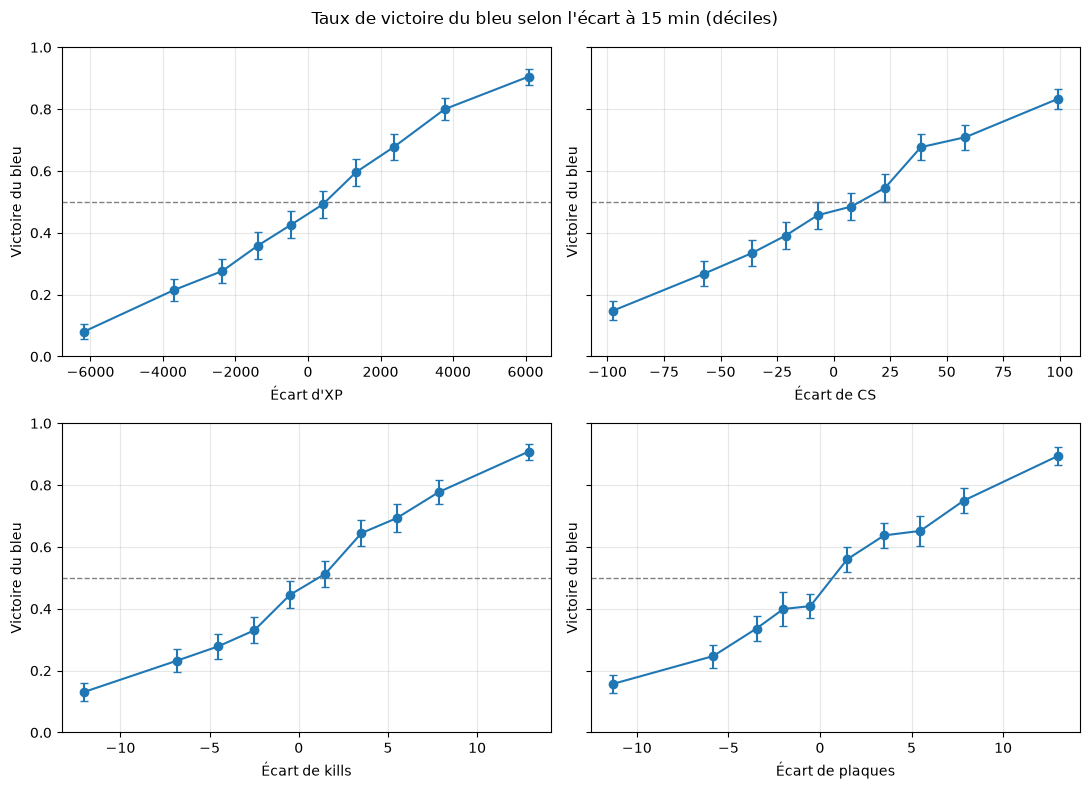

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for ax, (feature, label) in zip(axes.flat, [("xp_diff", "Écart d'XP"),
                                          ("cs_diff", "Écart de CS"),
                                          ("kills_diff", "Écart de kills"),
                                          ("plates_diff", "Écart de plaques")]):
    plot_winrate(ax, winrate_by_decile(state15, feature), label)
fig.suptitle("Taux de victoire du bleu selon l'écart à 15 min (déciles)")
fig.tight_layout()
plt.show()

In [12]:
for feature in ["towers_diff", "dragons_diff"]:
    t = state15.groupby(feature).agg(n=("blue_win", "size"), wins=("blue_win", "sum"))
    t = t[t["n"] >= 30]  # en dessous de 30 parties, le taux est trop instable
    t["victoire_bleu"], t["ic_bas"], t["ic_haut"] = prop_ci(t["wins"], t["n"])
    display(t.drop(columns="wins"))

,n,victoire_bleu,ic_bas,ic_haut
towers_diff,,,,
-3,148,0.122,0.069,0.174
-2,430,0.200,0.162,0.238
-1,1004,0.306,0.277,0.334
0,1570,0.469,0.445,0.494
1,994,0.646,0.616,0.676
2,477,0.809,0.774,0.844
3,153,0.830,0.771,0.890
4,30,0.967,0.902,1.031


,n,victoire_bleu,ic_bas,ic_haut
dragons_diff,,,,
-2,1152,0.257,0.232,0.282
-1,893,0.383,0.351,0.415
0,1238,0.502,0.475,0.530
1,776,0.619,0.584,0.653
2,790,0.761,0.731,0.791


### 5.3 Corrélations

Le coefficient de corrélation va de −1 à 1 : 0 = aucun lien linéaire, 1 = lien parfait.
La colonne `blue_win` dit quel écart est le plus lié à la victoire. Le reste du
tableau montre si les écarts sont liés **entre eux** : s'ils le sont fortement,
ils racontent en partie la même chose (un kill rapporte de l'or et de l'XP),
et il faudra en tenir compte à l'étape 11.

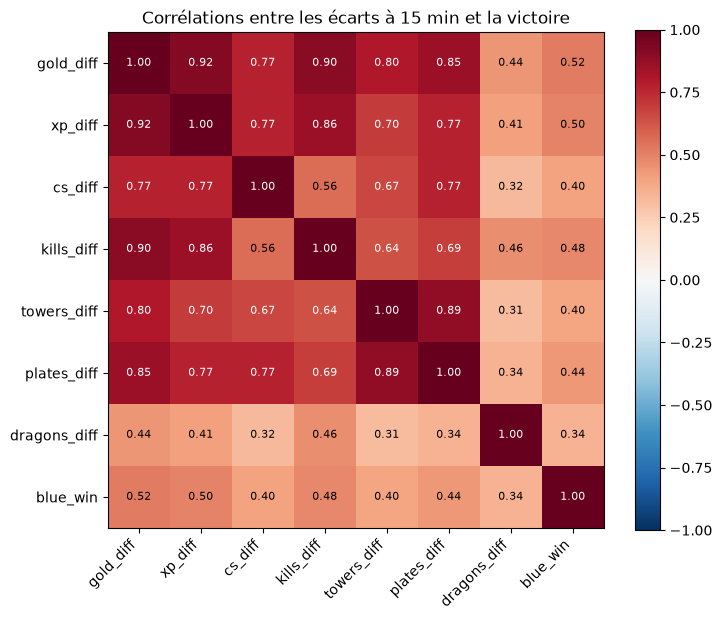

,corrélation avec blue_win
gold_diff,0.518
xp_diff,0.497
kills_diff,0.480
plates_diff,0.436
cs_diff,0.401
towers_diff,0.398
dragons_diff,0.344


In [13]:
corr = state15[FEATURES + ["blue_win"]].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im)
ax.set_title("Corrélations entre les écarts à 15 min et la victoire")
plt.show()

corr["blue_win"].drop("blue_win").sort_values(ascending=False).to_frame("corrélation avec blue_win")

## 6. Les « premiers » objectifs

La table `teams` dit quelle équipe a eu le premier sang, la première tour, le premier
dragon et le premier baron (sur toute la partie, pas seulement avant 15 min).
On mesure le taux de victoire de l'équipe qui l'a obtenu.

Attention : c'est une **association**, pas une cause. L'équipe qui prend la première
tour est souvent déjà devant en or ; une partie de son taux de victoire vient de là.
Séparer les deux effets, c'est le travail de l'étape 11.

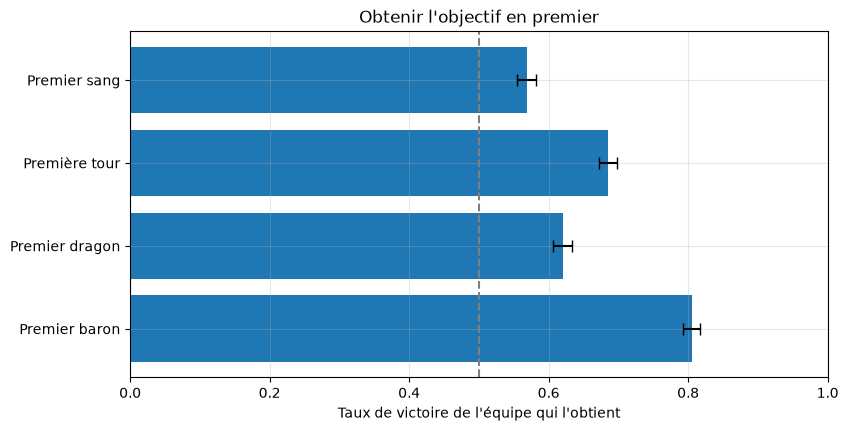

,objectif,equipes,victoire,ic_bas,ic_haut
0,Premier sang,4907,0.568,0.555,0.582
1,Première tour,4862,0.685,0.672,0.698
2,Premier dragon,4885,0.620,0.606,0.634
3,Premier baron,3881,0.805,0.793,0.818


In [14]:
rows = []
for col, label in [("first_blood", "Premier sang"), ("first_tower", "Première tour"),
                   ("first_dragon", "Premier dragon"), ("first_baron", "Premier baron")]:
    r = query(f"SELECT count(*) AS n, sum(win::int) AS wins FROM teams WHERE {col}")
    p, lo, hi = prop_ci(r["wins"][0], r["n"][0])
    rows.append({"objectif": label, "equipes": r["n"][0], "victoire": p, "ic_bas": lo, "ic_haut": hi})
firsts = pd.DataFrame(rows)

fig, ax = plt.subplots()
ax.barh(firsts["objectif"], firsts["victoire"],
        xerr=[firsts["victoire"] - firsts["ic_bas"], firsts["ic_haut"] - firsts["victoire"]],
        capsize=4)
ax.axvline(0.5, color="grey", linestyle="--")
ax.set_xlim(0, 1)
ax.set_xlabel("Taux de victoire de l'équipe qui l'obtient")
ax.set_title("Obtenir l'objectif en premier")
ax.invert_yaxis()
plt.show()
firsts

## 7. Champions

Les champions les plus joués et leur taux de victoire. Le point à retenir est la
largeur des intervalles de confiance : avec une centaine de parties par champion,
un taux de 53 % peut très bien cacher un vrai 50 %. On ne garde que les champions
joués au moins 100 fois.

173 champions différents joués.


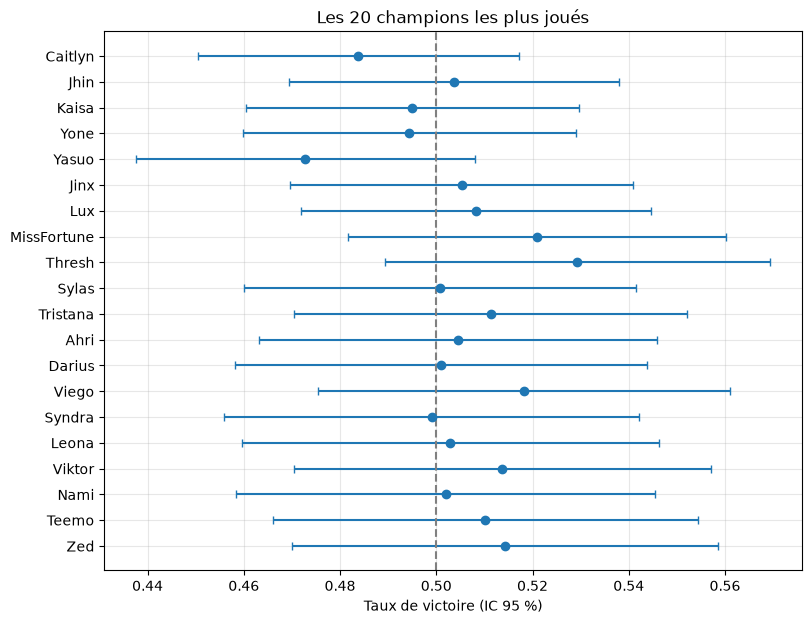

Champions joués 100 fois ou plus : 160, dont 10 dont l'intervalle exclut 50 %.


,champion,parties,taux_de_jeu,victoire,ic_bas,ic_haut
54,Caitlyn,864,0.176,0.484,0.450,0.517
161,Jhin,820,0.167,0.504,0.469,0.538
35,Kaisa,806,0.164,0.495,0.461,0.530
102,Yone,805,0.164,0.494,0.460,0.529
131,Yasuo,772,0.157,0.473,0.438,0.508
26,Jinx,758,0.154,0.505,0.470,0.541
77,Lux,728,0.148,0.508,0.472,0.545
90,MissFortune,620,0.126,0.521,0.482,0.560
129,Thresh,597,0.122,0.529,0.489,0.569
89,Sylas,579,0.118,0.501,0.460,0.542


In [15]:
champs = query("""
    SELECT p.champion_name AS champion,
           count(*) AS parties,
           sum(t.win::int) AS wins
    FROM participants p
    JOIN teams t USING (match_id, team_id)
    GROUP BY p.champion_name
""")
n_matches = len(matches)
print(f"{len(champs)} champions différents joués.")
champs["taux_de_jeu"] = champs["parties"] / n_matches
champs["victoire"], champs["ic_bas"], champs["ic_haut"] = prop_ci(champs["wins"], champs["parties"])

top = champs[champs["parties"] >= 100].sort_values("parties", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(9, 7))
ax.errorbar(top["victoire"], top["champion"],
            xerr=[top["victoire"] - top["ic_bas"], top["ic_haut"] - top["victoire"]],
            fmt="o", capsize=3)
ax.axvline(0.5, color="grey", linestyle="--")
ax.invert_yaxis()
ax.set_xlabel("Taux de victoire (IC 95 %)")
ax.set_title("Les 20 champions les plus joués")
plt.show()

excludes_50 = ((champs["parties"] >= 100) & ((champs["ic_haut"] < 0.5) | (champs["ic_bas"] > 0.5))).sum()
print(f"Champions joués 100 fois ou plus : {(champs['parties'] >= 100).sum()}, "
      f"dont {excludes_50} dont l'intervalle exclut 50 %.")
top.drop(columns="wins")

## 8. L'échantillon : joueurs répétés

La collecte « boule de neige » part d'un joueur et suit ses coéquipiers et adversaires.
Un même joueur peut donc apparaître dans plusieurs parties. Pour les tests
statistiques, les parties ne sont alors pas tout à fait indépendantes : à garder en tête.

In [16]:
repeat = query("""
    SELECT parties_du_joueur, count(*) AS joueurs
    FROM (SELECT puuid, count(*) AS parties_du_joueur FROM participants GROUP BY puuid) s
    GROUP BY parties_du_joueur
    ORDER BY parties_du_joueur
""")
repeat["part_des_lignes"] = repeat["parties_du_joueur"] * repeat["joueurs"] / (repeat["parties_du_joueur"] * repeat["joueurs"]).sum()
once = repeat.loc[repeat["parties_du_joueur"] == 1, "part_des_lignes"].sum()
print(f"{repeat['joueurs'].sum()} joueurs différents ; "
      f"{once:.0%} des places dans les parties sont occupées par un joueur vu une seule fois.")
repeat.head(10)

41173 joueurs différents ; 79% des places dans les parties sont occupées par un joueur vu une seule fois.


,parties_du_joueur,joueurs,part_des_lignes
0,1,38893,0.793
1,2,1826,0.074
2,3,116,0.007
3,4,17,0.001
4,5,12,0.001
5,6,10,0.001
6,7,3,0.000
7,8,5,0.001
8,9,5,0.001
9,10,4,0.001


## 9. Conclusions et questions pour l'étape 11

*Écrit le 30 oct. 2026 à partir de l'exécution sur toute la base (4 907 parties).*

**Les données**
- 4 907 parties classées solo/duo EUW, de juillet 2025 à octobre 2026. 98 % viennent des patchs 16.14 à 16.21 (au moins 200 parties chacun) ; les ~90 parties plus anciennes sont à écarter pour le modèle.
- Durée médiane : 30 min. 58 parties (1,2 %) finissent avant 15 min et sortent du modèle à 15 min. Pic net entre 15 et 16 min (109 parties) : les abandons au premier vote possible.
- 79 % des places sont occupées par un joueur vu une seule fois, le reste surtout par des joueurs vus 2 fois. Les parties sont donc presque indépendantes : la collecte boule de neige n'est pas un problème majeur.

**Côté bleu ou rouge**
- Le bleu gagne 48,3 % des parties (IC 95 % : 46,9 % à 49,7 %). 50 % est hors de l'intervalle : dans cet échantillon, le côté rouge a un léger avantage.
- Le rouge prend aussi plus de dragons avant 15 min (écart moyen −0,17 ; 1 152 parties où le rouge mène de 2 dragons, 790 où c'est le bleu).

**L'état à 15 min**
- Le taux de victoire suit une courbe en S selon l'écart d'or : 6,8 % pour le décile le plus en retard (−7 100 or en moyenne), 94,2 % pour le plus en avance (+7 100 or). À écart nul, le bleu gagne environ 46 %, cohérent avec l'avantage rouge.
- Corrélation avec la victoire : or 0,52, XP 0,50, kills 0,48, plaques 0,44, CS 0,40, bâtiments 0,40, dragons 0,34.
- Les écarts sont très liés entre eux : or–XP 0,92, or–kills 0,90, bâtiments–plaques 0,89. Ils mesurent en grande partie la même chose (l'avance). Les dragons sont le signal le plus à part (0,31 à 0,46 avec les autres).
- `towers_diff` compte tous les `BUILDING_KILL`, donc aussi les inhibiteurs : à renommer « bâtiments » ou à filtrer sur les tours à l'étape 11.

**Les « premiers » objectifs** (taux de victoire de l'équipe qui l'obtient) : premier sang 56,8 %, premier dragon 62,0 %, première tour 68,5 %, premier baron 80,5 %. Ce sont des associations, pas des causes.

**Champions** : 160 champions joués au moins 100 fois, dont 10 avec un intervalle qui exclut 50 %. Avec 160 intervalles à 95 %, on en attend environ 8 qui excluent 50 % par pur hasard : rien ne montre qu'un champion gagne vraiment plus qu'un autre ici.

**Questions pour l'étape 11** (régression logistique avec variables de contrôle, intervalles de confiance, parties des patchs 16.14 à 16.21 qui durent au moins 15 min) :
1. À écart d'or égal, l'XP, les kills et les dragons ajoutent-ils quelque chose à la prédiction ? Comme ces écarts sont très liés, on regardera la stabilité des coefficients.
2. La première tour garde-t-elle un effet une fois l'écart d'or à 15 min pris en compte, ou son taux de 68,5 % vient-il surtout de l'avance en or ?
3. L'avantage du côté rouge (51,7 %) tient-il quand on contrôle le patch, et passe-t-il par les dragons ?